# Co-fractionation thesis figures
Loads the input data and the existing CCprofiler results (CCprofiler is not rerun), recomputes only the tables needed for the figures and saves the main and supplementary figures as PDF.

In [1]:
from pathlib import Path
import re

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from pyteomics import mass, parser
from scipy.stats import mannwhitneyu
from procompa import get_project_root

PRJ_ROOT = get_project_root()
data_dir = PRJ_ROOT / 'data'
cofrac_data_dir = data_dir / 'cofrac'
portal_dir = data_dir / 'Complex_Portal'
sequence_data_dir = data_dir / 'iPTM_and_pLDDT'

NOTEBOOK_ROOT = Path('/cluster/project/beltrao/kdammer/master_thesis/notebooks')
WORK_DIR = NOTEBOOK_ROOT / 'ccprofiler_files'          # CCprofiler results from 32_ccprofiler_complex_evidence.ipynb
THESIS_FIGURE_DIR = NOTEBOOK_ROOT / 'Figures'          # the PDFs are written here

CF_FILES = {'highglu': 'highglu.tsv', 'nacl': 'nacl.tsv', 'ypd': 'ypd.tsv'}
CONDITIONS = list(CF_FILES)
COMPLEX_FILE = 'Saccharomyces_cerevisiae_ComplexTab.tsv'
SEQUENCE_FILE = 'all_CF_YM_yeast_proteins_uniprot_mapped_sequences.csv'
N_FRACTIONS = 60
FRACTION_COLUMNS = [str(i) for i in range(1, N_FRACTIONS + 1)]

# settings as in the CCprofiler notebook
WINDOW_KDA = (15, 1500)                     # resolvable range of the column
EARLY_FRACTION_MARGIN = 2                   # fractions kept before the calibrated window
MEMBRANE_TERMS = 'membrane'
CHROMATIN_TERMS = 'chromatin|nucleosome|histone'
MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN = 10
N_CAP_DRAWS = 100
PLOTTED_CAP_SEED = 0
STOICHIOMETRY_QUANTITIES = ['raw', 'per_mass', 'per_peptide']
OBSERVED_COLUMN = 'observed_log2_per_peptide'
MIN_PAIRS_PER_RATIO = 10

required_input_files = ([cofrac_data_dir / file_name for file_name in CF_FILES.values()]
                        + [portal_dir / COMPLEX_FILE, sequence_data_dir / SEQUENCE_FILE, WORK_DIR / 'calibration_curves.tsv']
                        + [WORK_DIR / f'complex_features_best_{condition}.tsv' for condition in CONDITIONS])
missing_input_files = [str(path) for path in required_input_files if not path.exists()]
assert not missing_input_files, f'missing input files: {missing_input_files}'
assert THESIS_FIGURE_DIR.is_dir(), f'{THESIS_FIGURE_DIR} not found'

## Input data

In [2]:
# --- elution profiles (protein groups such as [A;B] removed, as for CCprofiler) ---
def read_profiles(path):
    profiles = (pl.read_csv(path, separator='\t', infer_schema_length=0)
                  .with_columns(pl.col(FRACTION_COLUMNS).cast(pl.Float64).fill_null(0)))
    assert profiles.columns == ['ID', *FRACTION_COLUMNS], f'{path}: expected ID + fractions 1..{N_FRACTIONS}'
    assert profiles['ID'].is_unique().all(), f'{path}: duplicated IDs'
    return profiles.filter(~pl.col('ID').str.contains(';'))

profiles_wide = {condition: read_profiles(cofrac_data_dir / file_name) for condition, file_name in CF_FILES.items()}

# --- Complex Portal members with copy numbers ---
PARTICIPANT = re.compile(r'(\[[^\]]+\]|[^|()]+)\((\d+)\)')
UNIPROT = re.compile(r'^[OPQ][0-9][A-Z0-9]{3}[0-9]|^[A-NR-Z][0-9]')

portal = pl.read_csv(portal_dir / COMPLEX_FILE, separator='\t', quote_char=None, infer_schema_length=0)
member_rows, complex_rows = [], []
for complex_id, complex_name, identifiers, expanded in portal.select(
        '#Complex ac', 'Recommended name', 'Identifiers (and stoichiometry) of molecules in complex',
        'Expanded participant list').iter_rows():
    identifiers, expanded = identifiers or '', expanded or '-'
    participants = PARTICIPANT.findall(expanded if expanded != '-' else identifiers)
    proteins = {accession.split('-')[0]: int(copies) for accession, copies in participants if UNIPROT.match(accession)}
    has_paralogue_set = '[' in identifiers or '[' in expanded
    complex_rows.append(dict(complex_id=complex_id, n_proteins=len(proteins), has_non_protein=len(proteins) < len(participants),
                             copies_known=bool(proteins) and all(copies > 0 for copies in proteins.values())))
    if not has_paralogue_set:
        member_rows += [dict(complex_id=complex_id, complex_name=complex_name, protein_id=accession, copies=copies)
                        for accession, copies in proteins.items()]
complex_overview = pl.DataFrame(complex_rows)
complex_members = (pl.DataFrame(member_rows)
                     .join(complex_overview.select('complex_id', 'n_proteins', 'has_non_protein', 'copies_known'), on='complex_id')
                     .filter(pl.col('n_proteins') >= 2))

# --- calibration anchors ---
def same_copies(accessions, copies):
    return dict.fromkeys(accessions, copies)

SINGLE_PROTEIN_ANCHORS = {
    'Sod1 dimer': ('P00445', 2), 'Tpi1 dimer': ('P00942', 2), 'Eno1 dimer': ('P00924', 2),
    'Eno2 dimer': ('P00925', 2), 'Tdh3 tetramer': ('P00359', 4), 'Gln1 decamer': ('P32288', 10),
}
COMPLEX_ANCHORS = {
    'Prefoldin': same_copies(['P40005', 'P46988', 'P48363', 'P52553', 'P53900', 'Q04493'], 1),
    'Arp2/3': same_copies(['P32381', 'P33204', 'P38328', 'P40518', 'P47117', 'P53731', 'Q05933'], 1),
    'COPI coatomer': same_copies(['P32074', 'P40509', 'P41810', 'P41811', 'P43621', 'P53600', 'P53622'], 1),
    'MCM2-7': same_copies(['P24279', 'P29469', 'P29496', 'P30665', 'P38132', 'P53091'], 1),
    '20S proteasome': same_copies(['P22141', 'P30656', 'P38624', 'P30657', 'P40302', 'P40303', 'P23724',
                                   'P23639', 'P23638', 'P21242', 'P25043', 'P32379', 'P25451', 'P21243'], 2),
    'CCT / TRiC': same_copies(['P12612', 'P39076', 'P39077', 'P39078', 'P39079', 'P40413', 'P42943', 'P47079'], 2),
}
anchor_members = pl.DataFrame([dict(complex_id='ANCHOR_' + re.sub(r'\W+', '_', name), complex_name=name,
                                    protein_id=accession, copies=copies)
                               for name, subunits in COMPLEX_ANCHORS.items() for accession, copies in subunits.items()])

# --- protein masses and tryptic peptides ---
sequences = (pl.read_csv(sequence_data_dir / SEQUENCE_FILE)
               .select('uniprot_id', 'sequence')
               .drop_nulls('sequence')
               .with_columns(pl.col('sequence').str.replace_all('*', '', literal=True).str.strip_chars())
               .unique('uniprot_id', keep='first', maintain_order=True))

def n_tryptic_peptides(sequence):
    return len(parser.cleave(sequence, parser.expasy_rules['trypsin'], min_length=6, max_length=30))

protein_info = (sequences.select(
        protein_id=pl.col('uniprot_id'),
        mass_kda=pl.col('sequence').map_elements(lambda sequence: mass.calculate_mass(sequence=sequence, average=True) / 1000,
                                                 return_dtype=pl.Float64),
        n_tryptic_peptides=pl.col('sequence').map_elements(n_tryptic_peptides, return_dtype=pl.Int64))
    .with_columns(n_tryptic_peptides=pl.when(pl.col('n_tryptic_peptides') > 0).then(pl.col('n_tryptic_peptides'))))

# --- CCprofiler results (q <= 0.05, best feature per complex) ---
best_features = pl.concat([pl.read_csv(WORK_DIR / f'complex_features_best_{condition}.tsv', separator='\t')
                             .select(pl.lit(condition).alias('condition'), 'complex_id', 'complex_name', 'n_subunits_annotated',
                                     'n_subunits_detected', 'subunits_detected', 'left_pp', 'apex', 'right_pp',
                                     'coelution_score', 'qvalue')
                           for condition in CONDITIONS])
assert not best_features.select('condition', 'complex_id').is_duplicated().any(), 'more than one best feature per complex and condition'
print('inputs loaded')

inputs loaded


## Mass from elution
Prints the numbers used in the Results text.

In [3]:
# --- expected mass of the co-eluting subunits ---
feature_subunits = (best_features
    .filter(~pl.col('complex_id').str.starts_with('ANCHOR'))
    .with_columns(protein_id=pl.col('subunits_detected').str.split(';'))
    .explode('protein_id')
    .join(complex_members.select('complex_id', 'protein_id', 'copies', 'copies_known', 'has_non_protein'),
          on=['complex_id', 'protein_id'], how='left')
    .join(protein_info, on='protein_id', how='left'))
assert feature_subunits['copies'].null_count() == 0, 'a detected subunit is not a member of its complex'

complex_masses = (feature_subunits
    .group_by('condition', 'complex_id', 'complex_name', 'apex', 'n_subunits_detected', 'n_subunits_annotated', 'has_non_protein')
    .agg(copies_known=pl.col('copies_known').all(), all_masses_known=pl.col('mass_kda').is_not_null().all(),
         mass_detected_subunits_kda=(pl.col('copies') * pl.col('mass_kda')).sum())
    .filter('copies_known', 'all_masses_known')
    .drop('copies_known', 'all_masses_known'))

# --- membrane / chromatin annotation from the Complex Portal GO terms ---
complex_categories = (portal
    .select(complex_id='#Complex ac', go_annotations=pl.col('Go Annotations').fill_null('').str.to_lowercase())
    .with_columns(is_membrane=pl.col('go_annotations').str.contains(MEMBRANE_TERMS),
                  is_chromatin=pl.col('go_annotations').str.contains(CHROMATIN_TERMS))
    .with_columns(category=pl.when(pl.col('is_membrane') & pl.col('is_chromatin')).then(pl.lit('membrane + chromatin'))
                             .when('is_membrane').then(pl.lit('membrane'))
                             .when('is_chromatin').then(pl.lit('chromatin'))
                             .otherwise(pl.lit('other')))
    .select('complex_id', 'category'))
EXCLUDED_ABOVE_WINDOW = {'CPX-3207': 'Mitochondrial pyruvate dehydrogenase complex', 'CPX-1162': 'Fatty-acyl-CoA synthase'}
complex_masses_with_category = complex_masses.join(complex_categories, on='complex_id', how='left')
assert complex_masses_with_category['category'].null_count() == 0, 'complex missing from Complex Portal table'
assert set(EXCLUDED_ABOVE_WINDOW) <= set(complex_masses_with_category['complex_id']), 'an excluded complex is not in the table'
complex_masses_with_category = complex_masses_with_category.filter(~pl.col('complex_id').is_in(list(EXCLUDED_ABOVE_WINDOW)))

# --- apex of the cytosolic ribosomal subunits (median profile of their proteins) ---
CYTOSOLIC_RIBOSOME = {'CPX-1599': '40S', 'CPX-1601': '60S'}
UNIPROT_ANYWHERE = re.compile(r'[OPQ][0-9][A-Z0-9]{3}[0-9]|[A-NR-Z][0-9][A-Z][A-Z0-9]{2}[0-9]')
ribosome_accessions = {}
for complex_id, identifiers, expanded in (portal.filter(pl.col('#Complex ac').is_in(list(CYTOSOLIC_RIBOSOME)))
        .select('#Complex ac', 'Identifiers (and stoichiometry) of molecules in complex', 'Expanded participant list').iter_rows()):
    participant_text = expanded if expanded and expanded != '-' else identifiers
    ribosome_accessions[CYTOSOLIC_RIBOSOME[complex_id]] = set(UNIPROT_ANYWHERE.findall(participant_text))
ribosome_marker_rows = []
for condition, profiles in profiles_wide.items():
    for ribosome_subunit, accessions in ribosome_accessions.items():
        ribosome_profiles = profiles.filter(pl.col('ID').is_in(list(accessions))).select(FRACTION_COLUMNS).to_numpy()
        assert len(ribosome_profiles) > 0, f'no {ribosome_subunit} proteins measured in {condition}'
        median_profile = np.median(ribosome_profiles / ribosome_profiles.max(axis=1, keepdims=True), axis=0)
        ribosome_marker_rows.append(dict(condition=condition, subunit=ribosome_subunit,
                                         apex_of_median_profile=int(np.argmax(median_profile)) + 1))
ribosome_markers = pl.DataFrame(ribosome_marker_rows)

# --- numbers for the text: complexes with >= 2 subunits measured, detected, with expected mass ---
detection_count_rows = []
for condition in CONDITIONS:
    measured_protein_ids = profiles_wide[condition].filter(pl.sum_horizontal(FRACTION_COLUMNS) > 0)['ID'].to_list()
    detection_count_rows.append(dict(
        condition=condition,
        at_least_2_subunits_measured=(complex_members.filter(pl.col('protein_id').is_in(measured_protein_ids))
                                      .group_by('complex_id').len().filter(pl.col('len') >= 2).height),
        detected=best_features.filter((pl.col('condition') == condition) & ~pl.col('complex_id').str.starts_with('ANCHOR')).height,
        expected_mass_known=complex_masses.filter(pl.col('condition') == condition).height))
detection_counts = pl.DataFrame(detection_count_rows)

# --- calibration anchors ---
complex_anchor_points = (best_features
    .filter(pl.col('complex_id').str.starts_with('ANCHOR'))
    .with_columns(protein_id=pl.col('subunits_detected').str.split(';'))
    .explode('protein_id')
    .join(anchor_members.select('complex_id', 'protein_id', 'copies'), on=['complex_id', 'protein_id'])
    .join(protein_info, on='protein_id', how='left')
    .group_by('condition', 'complex_name', 'apex')
    .agg(mass_kda=(pl.col('copies') * pl.col('mass_kda')).sum(), all_masses_known=pl.col('mass_kda').is_not_null().all())
    .filter('all_masses_known')
    .select('condition', anchor=pl.col('complex_name'), fraction=pl.col('apex'), mass_kda='mass_kda', how=pl.lit('CCprofiler feature')))
single_anchor_rows = []
for condition, profiles in profiles_wide.items():
    for anchor_name, (accession, copies) in SINGLE_PROTEIN_ANCHORS.items():
        anchor_profile = profiles.filter(pl.col('ID') == accession)
        anchor_mass = protein_info.filter(pl.col('protein_id') == accession)
        if anchor_profile.height == 0 or anchor_mass.height == 0:
            continue
        single_anchor_rows.append(dict(condition=condition, anchor=anchor_name,
                                       fraction=int(np.argmax(anchor_profile.select(FRACTION_COLUMNS).to_numpy()[0])) + 1,
                                       mass_kda=copies * anchor_mass['mass_kda'][0], how='highest intensity'))
anchor_points = pl.concat([complex_anchor_points, pl.DataFrame(single_anchor_rows)]).sort('condition', 'fraction')
calibration_curves = pl.read_csv(WORK_DIR / 'calibration_curves.tsv', separator='\t')

# --- apparent vs expected mass ---
calibrated_fraction_range = (calibration_curves
    .filter(pl.col('mass_kda').is_between(*WINDOW_KDA))
    .group_by('condition')
    .agg(first_fraction_in_window=pl.col('fraction').min(), last_fraction_in_window=pl.col('fraction').max())
    .with_columns(first_fraction_used=pl.max_horizontal(pl.col('first_fraction_in_window') - EARLY_FRACTION_MARGIN, pl.lit(1))))
assert calibrated_fraction_range.height == len(CONDITIONS), 'calibration curve never inside the window for a condition'
COMPLEX_PORTAL_ANCHOR_DUPLICATES = ['CPX-607', 'CPX-2156', 'CPX-1652', 'CPX-2944', 'CPX-1671']
apparent_vs_expected_mass = (complex_masses_with_category
    .filter(~pl.col('complex_id').is_in(COMPLEX_PORTAL_ANCHOR_DUPLICATES))
    .join(calibration_curves.rename({'fraction': 'apex', 'mass_kda': 'apparent_mass_kda'}), on=['condition', 'apex'], how='left')
    .join(calibrated_fraction_range.select('condition', 'first_fraction_used', 'last_fraction_in_window'), on='condition', how='left')
    .with_columns(within_2_fold=(pl.col('apparent_mass_kda') / pl.col('mass_detected_subunits_kda')).log(2).abs() <= 1,
                  in_resolvable_range=pl.col('mass_detected_subunits_kda').is_between(*WINDOW_KDA),
                  apex_in_calibrated_range=pl.col('apex').is_between(pl.col('first_fraction_used'), pl.col('last_fraction_in_window'))))
assert apparent_vs_expected_mass['apparent_mass_kda'].null_count() == 0, 'an apex has no calibration value'
all_plotted_complexes = apparent_vs_expected_mass.filter(
    pl.col('in_resolvable_range') & pl.col('apex_in_calibrated_range') & (pl.col('category') == 'other'))

print(detection_counts)
print(all_plotted_complexes.group_by('condition').agg(n_complexes=pl.len(), share_within_2_fold=pl.col('within_2_fold').mean().round(2))
      .sort('condition'))

shape: (3, 4)
┌───────────┬──────────────────────────────┬──────────┬─────────────────────┐
│ condition ┆ at_least_2_subunits_measured ┆ detected ┆ expected_mass_known │
│ ---       ┆ ---                          ┆ ---      ┆ ---                 │
│ str       ┆ i64                          ┆ i64      ┆ i64                 │
╞═══════════╪══════════════════════════════╪══════════╪═════════════════════╡
│ highglu   ┆ 477                          ┆ 222      ┆ 115                 │
│ nacl      ┆ 486                          ┆ 267      ┆ 141                 │
│ ypd       ┆ 325                          ┆ 142      ┆ 85                  │
└───────────┴──────────────────────────────┴──────────┴─────────────────────┘
shape: (3, 3)
┌───────────┬─────────────┬─────────────────────┐
│ condition ┆ n_complexes ┆ share_within_2_fold │
│ ---       ┆ ---         ┆ ---                 │
│ str       ┆ u32         ┆ f64                 │
╞═══════════╪═════════════╪═════════════════════╡
│ highglu   ┆ 31    

## Stoichiometry from subunit intensities
Pairs pooled over all conditions. Prints the table values and AUCs (medians over the draws).

In [4]:
# --- summed subunit intensities within the peak boundaries ---
intensity_rows = []
for row in feature_subunits.filter('copies_known', pl.col('mass_kda').is_not_null()).iter_rows(named=True):
    peak_columns = [str(fraction) for fraction in range(row['left_pp'], row['right_pp'] + 1)]
    intensity = profiles_wide[row['condition']].filter(pl.col('ID') == row['protein_id']).select(peak_columns).to_numpy().sum()
    intensity_rows.append(dict(condition=row['condition'], complex_id=row['complex_id'], protein_id=row['protein_id'],
                               copies=row['copies'], raw=intensity, per_mass=intensity / row['mass_kda'],
                               per_peptide=intensity / row['n_tryptic_peptides'] if row['n_tryptic_peptides'] is not None else None))
subunit_intensities = pl.DataFrame(intensity_rows, infer_schema_length=None).filter(pl.col('raw') > 0)

# --- all subunit pairs within a complex, higher copy number first ---
pair_rows = []
for (condition, complex_id), complex_subunits in subunit_intensities.sort('protein_id').group_by('condition', 'complex_id', maintain_order=True):
    records = complex_subunits.to_dicts()
    for first_index in range(len(records)):
        for second_index in range(first_index + 1, len(records)):
            higher, lower = sorted([records[first_index], records[second_index]], key=lambda record: -record['copies'])
            pair = dict(condition=condition, complex_id=complex_id, protein_high_copies=higher['protein_id'],
                        protein_low_copies=lower['protein_id'], copies=f"{higher['copies']}:{lower['copies']}",
                        expected_log2=np.log2(higher['copies'] / lower['copies']))
            for quantity in STOICHIOMETRY_QUANTITIES:
                both_known = higher[quantity] is not None and lower[quantity] is not None
                pair[f'observed_log2_{quantity}'] = np.log2(higher[quantity] / lower[quantity]) if both_known else None
            pair_rows.append(pair)
all_subunit_pairs = pl.DataFrame(pair_rows, infer_schema_length=None)

# the same protein pair can occur in several complexes within a condition: keep it once, from the most significant complex
first_protein, second_protein = pl.col('protein_high_copies'), pl.col('protein_low_copies')
subunit_pairs = (all_subunit_pairs
    .join(best_features.select('condition', 'complex_id', 'qvalue', 'coelution_score'), on=['condition', 'complex_id'], how='left')
    .with_columns(pair_key_a=pl.when(first_protein < second_protein).then(first_protein).otherwise(second_protein),
                  pair_key_b=pl.when(first_protein < second_protein).then(second_protein).otherwise(first_protein))
    .sort(['qvalue', 'coelution_score', 'complex_id', 'pair_key_a', 'pair_key_b'], descending=[False, True, False, False, False])
    .unique(['condition', 'pair_key_a', 'pair_key_b'], keep='first', maintain_order=True)
    .drop('pair_key_a', 'pair_key_b')
    .sort('condition', 'complex_id', 'protein_high_copies', 'protein_low_copies'))     # fixed order, so the random draws are reproducible
assert subunit_pairs['qvalue'].null_count() == 0, 'a pair has no q-value'

pairs_with_all_quantities = subunit_pairs.drop_nulls([f'observed_log2_{quantity}' for quantity in STOICHIOMETRY_QUANTITIES])
equal_pairs_all_quantities = pairs_with_all_quantities.filter(pl.col('expected_log2') == 0)
unequal_pairs_all_quantities = pairs_with_all_quantities.filter(pl.col('expected_log2') > 0)

def cap_stoichiometry_pairs_per_protein(pairs, max_pairs_per_protein, seed):
    '''Go through the pairs in random order; keep a pair only if neither of its proteins has reached the cap.'''
    shuffled_pairs = pairs.sample(fraction=1.0, shuffle=True, seed=seed)
    kept_pairs_per_protein, keep_pair = {}, []
    for protein_high, protein_low in shuffled_pairs.select('protein_high_copies', 'protein_low_copies').iter_rows():
        keep = (kept_pairs_per_protein.get(protein_high, 0) < max_pairs_per_protein
                and kept_pairs_per_protein.get(protein_low, 0) < max_pairs_per_protein)
        if keep:
            kept_pairs_per_protein[protein_high] = kept_pairs_per_protein.get(protein_high, 0) + 1
            kept_pairs_per_protein[protein_low] = kept_pairs_per_protein.get(protein_low, 0) + 1
        keep_pair.append(keep)
    capped_pairs = shuffled_pairs.filter(pl.Series(keep_pair))
    assert capped_pairs.height > 0, 'cap removed every pair'
    return capped_pairs

def with_copy_ratio(pair_set):
    '''Add the reduced copy ratio (4:2 -> 2:1, 2:2 -> 1:1) and the absolute observed log2 ratio.'''
    copies_high = pair_set['copies'].str.extract(r'^(\d+):\d+$', 1).cast(pl.Int64).to_numpy()
    copies_low = pair_set['copies'].str.extract(r'^\d+:(\d+)$', 1).cast(pl.Int64).to_numpy()
    common_divisor = np.gcd(copies_high, copies_low)
    reduced_ratio = [f'{high}:{low}' for high, low in zip(copies_high // common_divisor, copies_low // common_divisor)]
    return pair_set.with_columns(copy_ratio=pl.Series(reduced_ratio), absolute_log2_ratio=pl.col(OBSERVED_COLUMN).abs())

def auc_higher_above_lower(lower_values, higher_values):
    '''Probability that a value of the higher group exceeds one of the lower group (ties count half).'''
    return mannwhitneyu(higher_values, lower_values, alternative='greater').statistic / (len(higher_values) * len(lower_values))

def roc_points(positive_values, negative_values):
    cut_offs = np.sort(np.unique(np.r_[positive_values, negative_values]))[::-1]
    true_positive_rate = np.r_[0, 1 - np.searchsorted(np.sort(positive_values), cut_offs, side='left') / len(positive_values)]
    false_positive_rate = np.r_[0, 1 - np.searchsorted(np.sort(negative_values), cut_offs, side='left') / len(negative_values)]
    return false_positive_rate, true_positive_rate

# --- table numbers: median over the capped draws ---
draw_metric_rows = []
for seed in range(N_CAP_DRAWS):
    equal_pairs_in_draw = cap_stoichiometry_pairs_per_protein(equal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed)
    unequal_pairs_in_draw = cap_stoichiometry_pairs_per_protein(unequal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed)
    draw_metrics = dict(seed=seed, n_unequal_pairs=unequal_pairs_in_draw.height, n_unequal_complexes=unequal_pairs_in_draw['complex_id'].n_unique(),
                        n_equal_pairs=equal_pairs_in_draw.height)
    for quantity in STOICHIOMETRY_QUANTITIES:
        draw_metrics[f'{quantity}_share_higher_copy_more_signal'] = float((unequal_pairs_in_draw[f'observed_log2_{quantity}'] > 0).mean())
        draw_metrics[f'{quantity}_equal_pairs_median_fold'] = float(2 ** equal_pairs_in_draw[f'observed_log2_{quantity}'].abs().median())
    draw_metric_rows.append(draw_metrics)
stoichiometry_table_medians = pl.DataFrame(draw_metric_rows).drop('seed').median()

# --- plotted draw and AUCs between copy ratios ---
capped_equal_pairs = cap_stoichiometry_pairs_per_protein(equal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, PLOTTED_CAP_SEED)
capped_unequal_pairs = cap_stoichiometry_pairs_per_protein(unequal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, PLOTTED_CAP_SEED)
plotted_draw_pairs = pl.concat([with_copy_ratio(capped_equal_pairs), with_copy_ratio(capped_unequal_pairs)])
ratio_classes = (plotted_draw_pairs.group_by('copy_ratio')
                 .agg(expected_log2=pl.col('expected_log2').first(), n_pairs=pl.len())
                 .sort('expected_log2'))
compared_ratios = ratio_classes.filter(pl.col('n_pairs') >= MIN_PAIRS_PER_RATIO)['copy_ratio'].to_list()
assert compared_ratios[0] == '1:1' and len(compared_ratios) >= 3, f'unexpected compared copy ratios: {compared_ratios}'
unequal_ratios = compared_ratios[1:]
comparisons_against_equal = [('1:1', unequal_ratio) for unequal_ratio in unequal_ratios]
neighbouring_comparisons = list(zip(unequal_ratios[:-1], unequal_ratios[1:]))

ratio_auc_rows = []
for seed in range(N_CAP_DRAWS):
    draw_pairs = pl.concat([
        with_copy_ratio(cap_stoichiometry_pairs_per_protein(equal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed)),
        with_copy_ratio(cap_stoichiometry_pairs_per_protein(unequal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed))])
    values_by_ratio = {ratio: draw_pairs.filter(pl.col('copy_ratio') == ratio)['absolute_log2_ratio'].to_numpy() for ratio in compared_ratios}
    for lower_ratio, higher_ratio in comparisons_against_equal + neighbouring_comparisons:
        if len(values_by_ratio[lower_ratio]) and len(values_by_ratio[higher_ratio]):
            ratio_auc_rows.append(dict(lower_ratio=lower_ratio, higher_ratio=higher_ratio,
                                       auc=auc_higher_above_lower(values_by_ratio[lower_ratio], values_by_ratio[higher_ratio])))
ratio_auc_summary = (pl.DataFrame(ratio_auc_rows)
    .group_by('lower_ratio', 'higher_ratio', maintain_order=True)
    .agg(n_draws=pl.len(), auc_median=pl.col('auc').median()))

with pl.Config(tbl_cols=-1, tbl_width_chars=200):
    print('table, median over draws:')
    print(stoichiometry_table_medians)
    print('AUCs between copy ratios, median over draws:')
    print(ratio_auc_summary.with_columns(pl.col('auc_median').round(2)))

table, median over draws:
shape: (1, 9)
┌─────────────────┬─────────────────────┬───────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬──────────────────────┐
│ n_unequal_pairs ┆ n_unequal_complexes ┆ n_equal_pairs ┆ raw_share_higher_copy ┆ raw_equal_pairs_media ┆ per_mass_share_higher ┆ per_mass_equal_pairs_ ┆ per_peptide_share_hig ┆ per_peptide_equal_pa │
│ ---             ┆ ---                 ┆ ---           ┆ _more_sig…            ┆ n_fold                ┆ _copy_mor…            ┆ median_fo…            ┆ her_copy_…            ┆ irs_median…          │
│ f64             ┆ f64                 ┆ f64           ┆ ---                   ┆ ---                   ┆ ---                   ┆ ---                   ┆ ---                   ┆ ---                  │
│                 ┆                     ┆               ┆ f64                   ┆ f64                   ┆ f64                   ┆ f64                   ┆ f6

## Stoichiometry of the fully detected predicted complexes
YM CCprofiler run (notebook 34), NaCl. Inputs for panel E, F and the candidate supplementary figure.

In [8]:
# --- fully detected complexes of the CCprofiler run with the yeast map complexes (34_cofrac_for_ym.ipynb), NaCl only ---
import ast
import json

YM_WORK_DIR = NOTEBOOK_ROOT / 'ccprofiler_files_ym'
COMBFOLD_RESULT_FILES = {
    'CP': data_dir / 'Pipeline' / '19_CP_pae_plddt_trimmed' / 'all_pdb_present_19_CP_pae_plddt_trimmed_pool_pipeline_complexes_combfold_results.csv',
    'YM': data_dir / 'Pipeline' / '22_YM_pae_trimmed' / 'all_pdb_present_22_YM_pae_trimmed_pool_pipeline_complexes_combfold_results.csv',
}
STOIC_RANKS = [1, 2, 3]
N_SUBUNITS_ANNOTATED_MIN = 3
N_FULLY_DETECTED_EXPECTED = 4
SUBUNIT_NOISE_SD_LOG2 = 0.78     # from equal pairs: median |log2| 0.74 -> pair SD 1.10 -> per subunit 1.10 / sqrt(2)
STRUCTURE_IMAGE_PATH = THESIS_FIGURE_DIR / 'pdb_structures' / 'co_frac_1652' / 'comparison_5a1u.png'   # panel F

required_stoichiometry_files = [YM_WORK_DIR / 'complex_features_best_nacl.tsv', YM_WORK_DIR / 'complexes_after_fraction_25_nacl.csv',
                                WORK_DIR / 'fraction_annotation.tsv', WORK_DIR / 'profiles_long_nacl.tsv',
                                STRUCTURE_IMAGE_PATH, *COMBFOLD_RESULT_FILES.values()]
missing_stoichiometry_files = [str(path) for path in required_stoichiometry_files if not path.exists()]
assert not missing_stoichiometry_files, f'missing input files: {missing_stoichiometry_files}'

# --- best NaCl feature, complexes eluting after fraction 25 with every subunit co-eluting (as in notebook 34) ---
predicted_complexes_after_fraction_25 = pl.read_csv(YM_WORK_DIR / 'complexes_after_fraction_25_nacl.csv')
fully_detected_features = (pl.read_csv(YM_WORK_DIR / 'complex_features_best_nacl.tsv', separator='\t')
    .select('complex_id', 'n_subunits_annotated', 'n_subunits_detected', 'subunits_detected', 'left_pp', 'apex', 'right_pp', 'qvalue')
    .join(predicted_complexes_after_fraction_25.select('complex_id'), on='complex_id', how='semi')
    .filter(pl.col('n_subunits_detected') == pl.col('n_subunits_annotated'),
            pl.col('n_subunits_annotated') >= N_SUBUNITS_ANNOTATED_MIN))
assert fully_detected_features.height == N_FULLY_DETECTED_EXPECTED, fully_detected_features['complex_id'].to_list()

# --- summed intensity per tryptic peptide within the peak boundaries ---
fraction_annotation_nacl = pl.read_csv(WORK_DIR / 'fraction_annotation.tsv', separator='\t')
profiles_long_nacl = (pl.read_csv(WORK_DIR / 'profiles_long_nacl.tsv', separator='\t')
                        .join(fraction_annotation_nacl, on='filename', how='left'))
assert profiles_long_nacl['fraction_number'].null_count() == 0, 'a file name has no fraction number'

fully_detected_subunit_intensities = (fully_detected_features
    .with_columns(protein_id=pl.col('subunits_detected').str.split(';'))
    .explode('protein_id')
    .join(profiles_long_nacl, on='protein_id', how='inner')
    .filter(pl.col('fraction_number').is_between(pl.col('left_pp'), pl.col('right_pp')))
    .group_by('complex_id', 'protein_id', 'left_pp', 'right_pp')
    .agg(summed_intensity=pl.col('intensity').sum(), n_fractions_summed=pl.len())
    .join(protein_info.select('protein_id', 'n_tryptic_peptides'), on='protein_id', how='left')
    .with_columns(intensity_per_peptide=pl.col('summed_intensity') / pl.col('n_tryptic_peptides')))
assert (fully_detected_subunit_intensities['n_fractions_summed']
        == fully_detected_subunit_intensities['right_pp'] - fully_detected_subunit_intensities['left_pp'] + 1).all(), 'fraction missing in peak'
assert fully_detected_subunit_intensities['n_tryptic_peptides'].null_count() == 0, 'subunit without sequence or tryptic peptide'
assert (fully_detected_subunit_intensities['summed_intensity'] > 0).all(), 'subunit without signal in its peak'
subunits_found_per_complex = (fully_detected_subunit_intensities.group_by('complex_id').agg(n_subunits_found=pl.len())
                              .join(fully_detected_features.select('complex_id', 'n_subunits_detected'), on='complex_id'))
assert (subunits_found_per_complex['n_subunits_found'] == subunits_found_per_complex['n_subunits_detected']).all(), subunits_found_per_complex

log2_intensity_per_complex = {
    complex_id: dict(zip(complex_subunits['protein_id'], np.log2(complex_subunits['intensity_per_peptide'].to_numpy())))
    for (complex_id,), complex_subunits in fully_detected_subunit_intensities.group_by('complex_id')
}


# --- Stoic predictions (ranks 1-3) of these complexes ---
def parse_stoic_prediction(prediction_string):
    '''{"P1":2,...},{"rank":1,...,"probability":0.9} -> ({protein: copies}, probability).'''
    copies_per_protein, rank_info = json.loads(f'[{prediction_string}]')
    return copies_per_protein, rank_info['probability']


def highest_cf_confidence(confidence_string):
    '''{0: 76.8, 1: 76.3} -> 76.8; {} (no assembly) -> None.'''
    confidence_per_assembly = ast.literal_eval(confidence_string) if confidence_string else {}
    return max(confidence_per_assembly.values()) if confidence_per_assembly else None


def load_stoic_predictions(complex_ids):
    combfold_results = (pl.concat([pl.read_csv(path, infer_schema_length=0).with_columns(source=pl.lit(source))
                                   for source, path in COMBFOLD_RESULT_FILES.items()], how='diagonal')
                          .filter(pl.col('complex_ac').is_in(complex_ids)))
    assert set(combfold_results['complex_ac']) == set(complex_ids), set(complex_ids) - set(combfold_results['complex_ac'])
    assert combfold_results['complex_ac'].is_unique().all(), 'complex in more than one CombFold result file'
    prediction_rows = []
    for result_row in combfold_results.iter_rows(named=True):
        for rank in STOIC_RANKS:
            copies_per_protein, probability = parse_stoic_prediction(result_row[f'pred_{rank}'])
            prediction_rows.append(dict(complex_id=result_row['complex_ac'], stoic_rank=rank, stoic_probability=probability,
                                        cf_confidence=highest_cf_confidence(result_row[f'CF_{rank}_confidence']),
                                        copies_per_protein=copies_per_protein))
    return prediction_rows


stoic_predictions_fully_detected = load_stoic_predictions(fully_detected_features['complex_id'].to_list())
for prediction in stoic_predictions_fully_detected:
    assert set(prediction['copies_per_protein']) == set(log2_intensity_per_complex[prediction['complex_id']]), \
        f"{prediction['complex_id']} rank {prediction['stoic_rank']}: predicted subunits differ from the detected subunits"
print('fully detected complexes (NaCl):', sorted(log2_intensity_per_complex))


fully detected complexes (NaCl): ['CPX-1652', 'CPX-1846', 'pred_CPX_547', 'pred_CPX_698']


## Figures

In [9]:
required_variables = [
    'complex_masses_with_category', 'ribosome_markers', 'anchor_points', 'calibration_curves', 'all_plotted_complexes',
    'WINDOW_KDA', 'N_FRACTIONS', 'CONDITIONS',
    'capped_equal_pairs', 'capped_unequal_pairs', 'equal_pairs_all_quantities', 'unequal_pairs_all_quantities',
    'cap_stoichiometry_pairs_per_protein', 'MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN', 'N_CAP_DRAWS',
    'OBSERVED_COLUMN', 'plotted_draw_pairs', 'ratio_auc_summary', 'comparisons_against_equal', 'neighbouring_comparisons',
    'roc_points', 'auc_higher_above_lower',
]
missing_variables = [name for name in required_variables if name not in globals()]
assert not missing_variables, f'run the analysis cells first, missing: {missing_variables}'

# figures are drawn at their final size, so font sizes in the PDF are the font sizes in the thesis.
# set this to \the\textwidth of the thesis (in LaTeX: \showthe\textwidth, then pt / 72.27 = inches)
FIGURE_WIDTH_INCHES = 6.2                 # text width of the thesis (157 mm), measured from the thesis PDF

# Paul Tol medium- and high-contrast schemes
TOL_BLUE, TOL_LIGHT_BLUE = '#004488', '#6699CC'
TOL_RED, TOL_DARK_RED, TOL_LIGHT_RED = '#BB5566', '#994455', '#EE99AA'
TOL_YELLOW, TOL_GREY = '#DDAA33', '#BBBBBB'
WINDOW_COLOR = '#EEEEEE'

CONDITION_LABELS = {'highglu': 'High glucose', 'nacl': 'NaCl', 'ypd': 'YPD'}
assert set(CONDITION_LABELS) == set(CONDITIONS), f'condition labels do not match CONDITIONS: {CONDITIONS}'
MAIN_CONDITION = 'nacl'
SUPPLEMENTARY_CONDITIONS = [condition for condition in CONDITIONS if condition != MAIN_CONDITION]

CATEGORY_STYLES = {
    'other': dict(label='Other', color=TOL_BLUE),
    'membrane': dict(label='Membrane', color=TOL_RED),
    'chromatin': dict(label='Chromatin', color=TOL_YELLOW),
    'membrane + chromatin': dict(label='Membrane, chromatin', color=TOL_LIGHT_RED),
}
assert set(complex_masses_with_category['category'].unique()) <= set(CATEGORY_STYLES), 'a complex category has no plot style'

ANCHOR_METHOD_STYLES = {
    'CCprofiler feature': dict(label='Hetero-oligomer', color=TOL_BLUE),
    'highest intensity': dict(label='Homo-oligomer', color=TOL_RED),
}
assert set(anchor_points['how'].unique()) <= set(ANCHOR_METHOD_STYLES), 'an anchor placement method has no plot style'

ALL_UNEQUAL_COLOR = '#222222'
RATIO_COLORS = {'2:1': TOL_LIGHT_BLUE, '3:1': TOL_BLUE, '6:1': TOL_DARK_RED}
plotted_unequal_ratios = sorted({higher for _, higher in comparisons_against_equal + neighbouring_comparisons})
assert set(plotted_unequal_ratios) <= set(RATIO_COLORS), f'add colours for copy ratios: {set(plotted_unequal_ratios) - set(RATIO_COLORS)}'

THESIS_STYLE = {
    'font.size': 9, 'axes.titlesize': 9, 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 7.5, 'legend.title_fontsize': 7.5, 'legend.frameon': False, 'legend.handlelength': 1.2,
    'legend.handletextpad': 0.4, 'legend.borderaxespad': 0.3, 'legend.labelspacing': 0.3,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.7,
    'xtick.major.width': 0.7, 'ytick.major.width': 0.7, 'pdf.fonttype': 42,
}
PANEL_LETTER_STYLE = dict(fontsize=11, fontweight='bold', va='bottom', ha='left')
PANEL_LETTER_OFFSET_INCHES = (0.48, 0.06)          # left of and above the top-left corner of each panel


PANEL_BOX_ASPECT = 0.82          # panel height / width; all panels share it, so rows and columns line up


def arrange_square_panels(figure, axes_grid, left, right, bottom, top, horizontal_space, vertical_space):
    '''All panels of equal size and shape, so rows and columns line up.'''
    for axis in np.ravel(axes_grid):
        axis.set_box_aspect(PANEL_BOX_ASPECT)
    figure.subplots_adjust(left=left, right=right, bottom=bottom, top=top, wspace=horizontal_space, hspace=vertical_space)


def add_panel_letters(figure, axes, letters):
    '''Letters at the same offset from every panel, so letters of one row or column line up.'''
    assert len(axes) == len(letters), 'one letter per panel'
    figure.canvas.draw()                                           # apply the square aspect before reading positions
    figure_width, figure_height = figure.get_size_inches()
    for axis, letter in zip(axes, letters):
        panel_position = axis.get_position()
        figure.text(panel_position.x0 - PANEL_LETTER_OFFSET_INCHES[0] / figure_width,
                    panel_position.y1 + PANEL_LETTER_OFFSET_INCHES[1] / figure_height, letter, **PANEL_LETTER_STYLE)

In [10]:
def draw_apex_vs_expected_mass(axis, condition):
    complexes_in_condition = complex_masses_with_category.filter(pl.col('condition') == condition)
    assert complexes_in_condition.height > 0, f'no complexes with known mass in {condition}'
    axis.axhspan(*WINDOW_KDA, color=WINDOW_COLOR, lw=0, zorder=0)
    ribosome_apexes = (ribosome_markers.filter(pl.col('condition') == condition)
                       .group_by('apex_of_median_profile').agg(pl.col('subunit').sort()))
    for apex, ribosome_subunits in ribosome_apexes.iter_rows():
        axis.axvline(apex, color='black', ls='--', lw=0.8, zorder=1)
        axis.text(apex, 1.01, 'Ribosome', ha='center', va='bottom', fontsize=7.5, transform=axis.get_xaxis_transform())
    for category, style in CATEGORY_STYLES.items():
        complexes_in_category = complexes_in_condition.filter(pl.col('category') == category)
        if complexes_in_category.height == 0:
            continue
        axis.scatter(complexes_in_category['apex'], complexes_in_category['mass_detected_subunits_kda'], s=10,
                     color=style['color'], lw=0, zorder=2, label=f"{style['label']} ({complexes_in_category.height})")
    largest_mass = complexes_in_condition['mass_detected_subunits_kda'].max()
    axis.set(xlim=(0, N_FRACTIONS + 1), yscale='log', xlabel='Elution apex (fraction)', ylabel='Expected mass (kDa)')
    axis.set_ylim(top=max(largest_mass, WINDOW_KDA[1]) * 8)          # headroom for the legend above the data
    axis.legend(loc='upper right', markerscale=1.3)


def draw_calibration(axis, condition, label_anchor_names=True):
    anchors_in_condition = anchor_points.filter(pl.col('condition') == condition)
    calibration_in_condition = calibration_curves.filter(pl.col('condition') == condition)
    assert anchors_in_condition.height > 0 and calibration_in_condition.height > 0, f'no calibration for {condition}'
    axis.axhspan(*WINDOW_KDA, color=WINDOW_COLOR, lw=0, zorder=0)
    axis.plot(calibration_in_condition['fraction'], calibration_in_condition['mass_kda'], color='black', lw=1, zorder=1)
    for placement_method, style in ANCHOR_METHOD_STYLES.items():
        anchors_with_method = anchors_in_condition.filter(pl.col('how') == placement_method)
        if anchors_with_method.height == 0:
            continue
        axis.scatter(anchors_with_method['fraction'], anchors_with_method['mass_kda'], s=16, color=style['color'],
                     lw=0, zorder=2, label=f'{style["label"]} ({anchors_with_method.height})')
    axis.set(xlim=(0, CALIBRATION_X_LIMIT if label_anchor_names else N_FRACTIONS + 1), xticks=[0, 20, 40, 60],
             yscale='log', ylim=(8, 5000), xlabel='Elution fraction', ylabel='Anchor mass (kDa)')
    axis.spines['bottom'].set_bounds(0, N_FRACTIONS)
    axis.legend(loc='lower left', markerscale=1.1)
    if label_anchor_names:
        label_anchors(axis, anchors_in_condition)


ANCHOR_SHORT_NAMES = {
    'Sod1 dimer': 'Sod1', 'Tpi1 dimer': 'Tpi1', 'Eno1 dimer': 'Eno1', 'Eno2 dimer': 'Eno2', 'Tdh3 tetramer': 'Tdh3',
    'Gln1 decamer': 'Gln1', 'Prefoldin': 'Prefoldin', 'Arp2/3': 'Arp2/3', 'COPI coatomer': 'COPI', 'MCM2-7': 'MCM2–7',
    '20S proteasome': '20S', 'CCT / TRiC': 'CCT',
}
ANCHOR_LABEL_FONT_SIZE = 6.5
ANCHOR_LABEL_SPACING_POINTS = 7.5          # minimal vertical distance between two labels
ANCHOR_LABEL_COLUMN_FRACTION = 61          # labels are stacked in a column right of the data, connected by thin lines
CALIBRATION_X_LIMIT = 72                   # room for the label column; the fraction axis is still ticked up to 60


def label_anchors(axis, anchors_in_condition):
    '''Labels in one column right of the points, ordered like the points and pushed apart so they do not overlap.'''
    assert set(anchors_in_condition['anchor']) <= set(ANCHOR_SHORT_NAMES), \
        f'add short names for anchors: {set(anchors_in_condition["anchor"]) - set(ANCHOR_SHORT_NAMES)}'
    # anchors at the same position (e.g. Eno1 and Eno2) share one label
    anchor_groups = (anchors_in_condition
        .with_columns(short_name=pl.col('anchor').replace_strict(ANCHOR_SHORT_NAMES))
        .group_by('fraction', 'mass_kda')
        .agg(label=pl.col('short_name').sort().str.join(', '))
        .to_dicts())
    axis.figure.canvas.draw()                                          # final panel size before converting to points
    points_per_pixel = 72 / axis.figure.dpi
    for anchor_group in anchor_groups:
        anchor_group['point_y_points'] = axis.transData.transform((anchor_group['fraction'], anchor_group['mass_kda']))[1] * points_per_pixel
    anchor_groups.sort(key=lambda group: group['point_y_points'])
    label_y_points = []
    for anchor_group in anchor_groups:
        label_y_points.append(max(anchor_group['point_y_points'],
                                  label_y_points[-1] + ANCHOR_LABEL_SPACING_POINTS if label_y_points else -np.inf))
    axis_top_points = axis.get_window_extent().y1 * points_per_pixel - 3
    overshoot = max(0.0, label_y_points[-1] - axis_top_points)               # keep the column inside the panel
    label_y_points = [label_y - overshoot for label_y in label_y_points]
    for repeat in range(len(label_y_points)):                                 # restore the spacing at the bottom after the shift
        for index in range(len(label_y_points) - 2, -1, -1):
            label_y_points[index] = min(label_y_points[index], label_y_points[index + 1] - ANCHOR_LABEL_SPACING_POINTS)
    column_x_pixels = axis.transData.transform((ANCHOR_LABEL_COLUMN_FRACTION, 1))[0]
    for anchor_group, label_y in zip(anchor_groups, label_y_points):
        point_x_pixels = axis.transData.transform((anchor_group['fraction'], anchor_group['mass_kda']))[0]
        axis.annotate(anchor_group['label'], (anchor_group['fraction'], anchor_group['mass_kda']),
                      xytext=((column_x_pixels - point_x_pixels) * points_per_pixel, label_y - anchor_group['point_y_points']),
                      textcoords='offset points', ha='left', va='center', fontsize=ANCHOR_LABEL_FONT_SIZE, zorder=3,
                      arrowprops=dict(arrowstyle='-', lw=0.4, color='0.55', shrinkA=1, shrinkB=2.5))


apparent_mass_axis_range = np.array([
    min(all_plotted_complexes['mass_detected_subunits_kda'].min(), all_plotted_complexes['apparent_mass_kda'].min()) / 1.5,
    max(all_plotted_complexes['mass_detected_subunits_kda'].max(), all_plotted_complexes['apparent_mass_kda'].max()) * 1.5])


def draw_apparent_vs_expected_mass(axis, condition):
    complexes_in_condition = all_plotted_complexes.filter(pl.col('condition') == condition)
    assert complexes_in_condition.height > 0, f'no complexes in the calibrated range for {condition}'
    share_within_two_fold = complexes_in_condition['within_2_fold'].mean()
    axis.fill_between(apparent_mass_axis_range, apparent_mass_axis_range / 2, apparent_mass_axis_range * 2,
                      color=WINDOW_COLOR, lw=0, zorder=0)
    axis.plot(apparent_mass_axis_range, apparent_mass_axis_range, color='black', ls='--', lw=0.8, zorder=1)
    axis.scatter(complexes_in_condition['mass_detected_subunits_kda'], complexes_in_condition['apparent_mass_kda'],
                 s=12, color=TOL_BLUE, lw=0, zorder=2)
    axis.text(0.04, 0.96, f'n = {complexes_in_condition.height}\n{share_within_two_fold:.0%} within two-fold',
              transform=axis.transAxes, ha='left', va='top', fontsize=7.5)
    axis.set(xscale='log', yscale='log', xlim=apparent_mass_axis_range, ylim=apparent_mass_axis_range,
             xlabel='Expected mass (kDa)', ylabel='Apparent mass (kDa)')


MASS_PANEL_FUNCTIONS = [draw_apex_vs_expected_mass, draw_calibration, draw_apparent_vs_expected_mass]
SQUARE_LAYOUT = dict(left=0.085, right=0.995, horizontal_space=0.42)

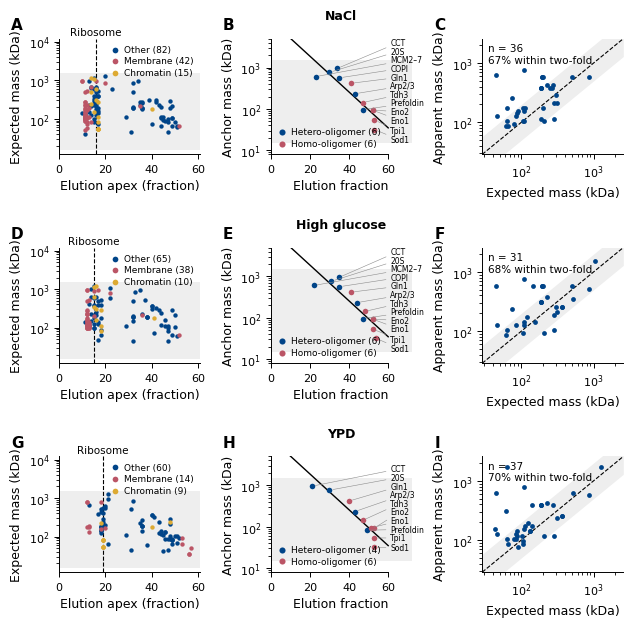

In [11]:
# supplementary figure: all three mass panels for every condition, one row per condition (NaCl first)
SUPPLEMENTARY_MASS_CONDITIONS = [MAIN_CONDITION] + SUPPLEMENTARY_CONDITIONS
SUPPLEMENTARY_MASS_PANEL_FUNCTIONS = MASS_PANEL_FUNCTIONS          # with anchor names
SUPPLEMENTARY_ANCHOR_LABEL_FONT_SIZE = 5.5                          # smaller than in the main figure, the panels are smaller
SUPPLEMENTARY_ANCHOR_LABEL_SPACING_POINTS = 6.2
main_anchor_label_font_size, main_anchor_label_spacing_points = ANCHOR_LABEL_FONT_SIZE, ANCHOR_LABEL_SPACING_POINTS
ANCHOR_LABEL_FONT_SIZE, ANCHOR_LABEL_SPACING_POINTS = SUPPLEMENTARY_ANCHOR_LABEL_FONT_SIZE, SUPPLEMENTARY_ANCHOR_LABEL_SPACING_POINTS
with plt.rc_context({**THESIS_STYLE, 'legend.fontsize': 6.5}):     # slightly smaller legends, so they do not touch the anchor names
    supplementary_mass_figure, supplementary_mass_axes = plt.subplots(
        len(SUPPLEMENTARY_MASS_CONDITIONS), 3, figsize=(FIGURE_WIDTH_INCHES, 0.335 * FIGURE_WIDTH_INCHES * len(SUPPLEMENTARY_MASS_CONDITIONS)))
    arrange_square_panels(supplementary_mass_figure, supplementary_mass_axes, left=0.085, right=0.995, bottom=0.07, top=0.95,
                          horizontal_space=0.5, vertical_space=0.6)
    for row_axes, condition in zip(supplementary_mass_axes, SUPPLEMENTARY_MASS_CONDITIONS):
        for axis, draw_panel in zip(row_axes, SUPPLEMENTARY_MASS_PANEL_FUNCTIONS):
            draw_panel(axis, condition)
        row_axes[1].set_title(CONDITION_LABELS[condition], pad=14, fontweight='bold')
    add_panel_letters(supplementary_mass_figure, list(np.ravel(supplementary_mass_axes)), 'ABCDEFGHI')
    supplementary_mass_figure.savefig(THESIS_FIGURE_DIR / 'cofrac_mass_supplementary.pdf', bbox_inches='tight')
    plt.show()
ANCHOR_LABEL_FONT_SIZE, ANCHOR_LABEL_SPACING_POINTS = main_anchor_label_font_size, main_anchor_label_spacing_points   # back to the main-figure sizes

In [14]:
# panels E (candidate stoichiometries of one complex) and F (structure), also used for the supplementary figure
for variable_name in ['log2_intensity_per_complex', 'stoic_predictions_fully_detected', 'SUBUNIT_NOISE_SD_LOG2', 'STRUCTURE_IMAGE_PATH']:
    assert variable_name in globals(), f'run the stoichiometry input cell first ({variable_name} missing)'

STOICHIOMETRY_EXAMPLE_COMPLEX = 'CPX-1652'          # panel E
assert STOICHIOMETRY_EXAMPLE_COMPLEX in log2_intensity_per_complex, f'{STOICHIOMETRY_EXAMPLE_COMPLEX} is not fully detected'
SINGLE_COPY_COLOR, MULTI_COPY_COLOR = TOL_BLUE, TOL_RED
CANDIDATE_TITLES = {'all 1': 'All single copy', 1: 'Stoic rank 1', 2: 'Stoic rank 2', 3: 'Stoic rank 3'}
assert set(STOIC_RANKS) <= set(CANDIDATE_TITLES), 'add a title for every Stoic rank'


def stoichiometry_candidates(complex_id):
    '''All subunits as single copies, then the Stoic predictions in rank order.'''
    proteins = log2_intensity_per_complex[complex_id]
    stoic_predictions_of_complex = sorted((prediction for prediction in stoic_predictions_fully_detected
                                           if prediction['complex_id'] == complex_id), key=lambda prediction: prediction['stoic_rank'])
    assert stoic_predictions_of_complex, f'no Stoic predictions for {complex_id}'
    candidates = [(CANDIDATE_TITLES['all 1'], dict.fromkeys(proteins, 1))]
    candidates += [(CANDIDATE_TITLES[prediction['stoic_rank']], prediction['copies_per_protein'])
                   for prediction in stoic_predictions_of_complex]
    for candidate_title, copies_per_protein in candidates:
        assert set(copies_per_protein) == set(proteins), (complex_id, candidate_title)
    return candidates


def draw_stoichiometry_candidates(axes_row, complex_id, tick_label_size, row_label=None):
    '''One panel per candidate stoichiometry, centred log2 intensity per predicted copy for every subunit.'''
    log2_intensity_per_protein = log2_intensity_per_complex[complex_id]
    proteins_by_intensity = sorted(log2_intensity_per_protein, key=log2_intensity_per_protein.get, reverse=True)
    candidates = stoichiometry_candidates(complex_id)
    assert len(candidates) == len(axes_row), f'{complex_id}: {len(candidates)} candidates for {len(axes_row)} panels'
    for axis, (candidate_title, copies_per_protein) in zip(axes_row, candidates):
        log2_per_copy = np.array([log2_intensity_per_protein[protein] - np.log2(copies_per_protein[protein])
                                  for protein in proteins_by_intensity])
        centred_log2_per_copy = log2_per_copy - log2_per_copy.mean()
        typical_fold_deviation = 2 ** np.sqrt((centred_log2_per_copy ** 2).mean())
        axis.axhspan(-SUBUNIT_NOISE_SD_LOG2, SUBUNIT_NOISE_SD_LOG2, color=WINDOW_COLOR, lw=0, zorder=0)
        axis.axhline(0, color=TOL_GREY, lw=0.7, zorder=1)
        point_colors = [MULTI_COPY_COLOR if copies_per_protein[protein] > 1 else SINGLE_COPY_COLOR for protein in proteins_by_intensity]
        axis.scatter(range(len(proteins_by_intensity)), centred_log2_per_copy, c=point_colors, s=14, lw=0, zorder=2)
        axis.set_xticks(range(len(proteins_by_intensity)),
                        [f'{protein} ({copies_per_protein[protein]})' for protein in proteins_by_intensity],
                        rotation=90, fontsize=tick_label_size)
        axis.set_xlim(-0.6, len(proteins_by_intensity) - 0.4)
        axis.set_title(f'{candidate_title}\n{typical_fold_deviation:.1f}-fold deviation', fontsize=tick_label_size + 0.5)
        axis.tick_params(axis='y', labelleft=axis is axes_row[0])
    y_label = 'Centred log$_2$ intensity\nper copy'
    axes_row[0].set_ylabel(y_label if row_label is None else f'{row_label}\n{y_label}')


def stoichiometry_legend_handles():
    return [plt.Line2D([], [], marker='o', ls='', ms=4, mew=0, color=SINGLE_COPY_COLOR, label='1 predicted copy'),
            plt.Line2D([], [], marker='o', ls='', ms=4, mew=0, color=MULTI_COPY_COLOR, label='> 1 predicted copies'),
            plt.Rectangle((0, 0), 1, 1, color=WINDOW_COLOR, label='Expected scatter (±1 SD)')]


def read_structure_image(path):
    '''PNG with its empty (transparent or white) margin cropped away.'''
    structure_pixels = plt.imread(path)
    assert structure_pixels.ndim == 3 and structure_pixels.shape[2] in (3, 4), f'{path}: expected an RGB or RGBA image'
    has_content = (structure_pixels[..., :3] < 0.98).any(axis=2)
    if structure_pixels.shape[2] == 4:
        has_content &= structure_pixels[..., 3] > 0.02
    content_rows, content_columns = np.flatnonzero(has_content.any(axis=1)), np.flatnonzero(has_content.any(axis=0))
    assert len(content_rows) and len(content_columns), f'{path}: image is empty'
    return structure_pixels[content_rows[0]:content_rows[-1] + 1, content_columns[0]:content_columns[-1] + 1]


def draw_structure(axis, structure_pixels):
    axis.imshow(structure_pixels, interpolation='none')
    axis.set_anchor('W')                     # left edge of the image in line with the panels above, so the letter lines up
    axis.axis('off')



unequal vs equal, AUC median 0.69 (2.5–97.5%: 0.68–0.70) over 100 draws
main figure height 24.8 cm


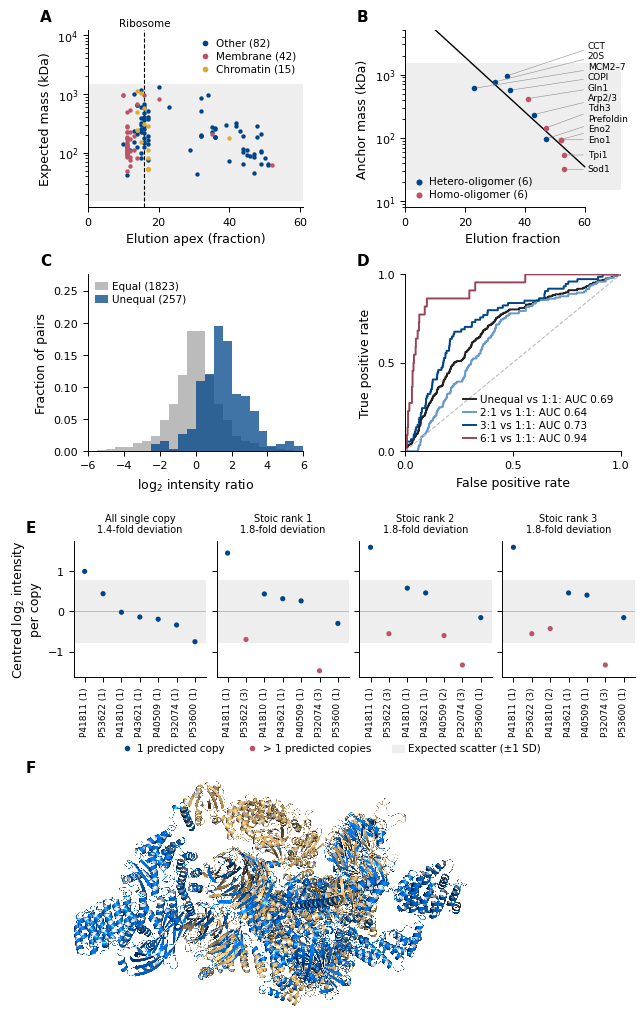

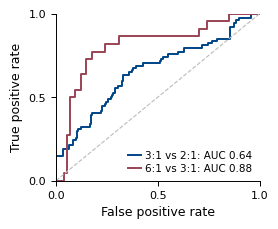

In [15]:
# stoichiometry, pooled over all conditions; curves from one capped draw, AUCs as median over all draws
overall_auc_per_draw = []
for seed in range(N_CAP_DRAWS):
    equal_pairs_in_draw = cap_stoichiometry_pairs_per_protein(equal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed)
    unequal_pairs_in_draw = cap_stoichiometry_pairs_per_protein(unequal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed)
    overall_auc_per_draw.append(auc_higher_above_lower(equal_pairs_in_draw[OBSERVED_COLUMN].abs().to_numpy(),
                                                       unequal_pairs_in_draw[OBSERVED_COLUMN].abs().to_numpy()))
overall_auc_per_draw = np.array(overall_auc_per_draw)
overall_auc_median = float(np.median(overall_auc_per_draw))
print(f'unequal vs equal, AUC median {overall_auc_median:.2f} '
      f'(2.5–97.5%: {np.quantile(overall_auc_per_draw, 0.025):.2f}–{np.quantile(overall_auc_per_draw, 0.975):.2f}) '
      f'over {N_CAP_DRAWS} draws')

ratio_auc_medians = {(row['lower_ratio'], row['higher_ratio']): row['auc_median']
                     for row in ratio_auc_summary.iter_rows(named=True)}


def draw_ratio_histogram(axis):
    equal_ratios = capped_equal_pairs[OBSERVED_COLUMN].to_numpy()
    unequal_ratios = capped_unequal_pairs[OBSERVED_COLUMN].to_numpy()
    histogram_bins = np.arange(-6, 6.1, 0.5)
    mirrored_equal_ratios = np.r_[equal_ratios, -equal_ratios]          # orientation of an equal pair is arbitrary
    axis.hist(mirrored_equal_ratios, histogram_bins, weights=np.full(len(mirrored_equal_ratios), 1 / len(mirrored_equal_ratios)),
              color=TOL_GREY, label=f'Equal ({len(equal_ratios)})')
    axis.hist(unequal_ratios, histogram_bins, weights=np.full(len(unequal_ratios), 1 / len(unequal_ratios)),
              color=TOL_BLUE, alpha=0.75, label=f'Unequal ({len(unequal_ratios)})')
    axis.set(xlim=(-6, 6), xlabel='log$_2$ intensity ratio', ylabel='Fraction of pairs')
    axis.set_ylim(top=axis.get_ylim()[1] * 1.35)                  # headroom for the legend above the bars
    axis.legend(loc='upper left')


def draw_roc_frame(axis):
    axis.plot([0, 1], [0, 1], color=TOL_GREY, ls='--', lw=0.8)
    axis.set(xlim=(0, 1), ylim=(0, 1), xticks=[0, 0.5, 1], yticks=[0, 0.5, 1],
             xlabel='False positive rate', ylabel='True positive rate')
    axis.legend(loc='lower right')


def draw_rocs_against_equal(axis):
    false_positive_rate, true_positive_rate = roc_points(capped_unequal_pairs[OBSERVED_COLUMN].abs().to_numpy(),
                                                         capped_equal_pairs[OBSERVED_COLUMN].abs().to_numpy())
    axis.plot(false_positive_rate, true_positive_rate, color=ALL_UNEQUAL_COLOR, lw=1.4, label=f'Unequal vs 1:1: AUC {overall_auc_median:.2f}')
    for lower_ratio, higher_ratio in comparisons_against_equal:
        draw_ratio_roc(axis, lower_ratio, higher_ratio)
    draw_roc_frame(axis)


def draw_ratio_roc(axis, lower_ratio, higher_ratio):
    lower_values = plotted_draw_pairs.filter(pl.col('copy_ratio') == lower_ratio)['absolute_log2_ratio'].to_numpy()
    higher_values = plotted_draw_pairs.filter(pl.col('copy_ratio') == higher_ratio)['absolute_log2_ratio'].to_numpy()
    assert len(lower_values) > 0 and len(higher_values) > 0, f'no pairs for {higher_ratio} vs {lower_ratio}'
    assert (lower_ratio, higher_ratio) in ratio_auc_medians, f'no AUC summary for {higher_ratio} vs {lower_ratio}'
    false_positive_rate, true_positive_rate = roc_points(higher_values, lower_values)
    axis.plot(false_positive_rate, true_positive_rate, color=RATIO_COLORS[higher_ratio], lw=1.4,
              label=f'{higher_ratio} vs {lower_ratio}: AUC {ratio_auc_medians[(lower_ratio, higher_ratio)]:.2f}')


def draw_neighbouring_rocs(axis):
    for lower_ratio, higher_ratio in neighbouring_comparisons:
        draw_ratio_roc(axis, lower_ratio, higher_ratio)
    draw_roc_frame(axis)


# main figure: NaCl elution vs mass (A), calibration (B), intensity ratios (C), ROC against equal pairs (D),
# candidate stoichiometries of CPX-1652 (E), structure (F)
STRUCTURE_PANEL_WIDTH_SHARE = 0.7          # width of panel F relative to the text width
structure_pixels = read_structure_image(STRUCTURE_IMAGE_PATH)
structure_height_inches = (0.905 * FIGURE_WIDTH_INCHES * STRUCTURE_PANEL_WIDTH_SHARE
                           * structure_pixels.shape[0] / structure_pixels.shape[1])
# rows in inches; the first row has the size of the former 2 x 2 figure without margins, the gaps hold axis labels and titles
MAIN_ROW_HEIGHTS_INCHES = {'mass and ratio panels': 0.78 * FIGURE_WIDTH_INCHES * (0.95 - 0.08), 'gap above E': 0.9,
                           'stoichiometry candidates': 2.2, 'gap above F': 0.2, 'structure': structure_height_inches}
with plt.rc_context(THESIS_STYLE):
    main_figure = plt.figure(figsize=(FIGURE_WIDTH_INCHES, sum(MAIN_ROW_HEIGHTS_INCHES.values())))
    main_figure_rows = main_figure.add_gridspec(len(MAIN_ROW_HEIGHTS_INCHES), 1, height_ratios=list(MAIN_ROW_HEIGHTS_INCHES.values()),
                                                left=0.085, right=0.99, bottom=0, top=1, hspace=0)
    mass_and_ratio_grid = main_figure_rows[0].subgridspec(2, 2, wspace=0.3, hspace=0.38)
    main_axes = np.array([[main_figure.add_subplot(mass_and_ratio_grid[row, column]) for column in range(2)] for row in range(2)])
    for axis in main_axes.ravel():
        axis.set_box_aspect(PANEL_BOX_ASPECT)
    draw_apex_vs_expected_mass(main_axes[0, 0], MAIN_CONDITION)
    draw_calibration(main_axes[0, 1], MAIN_CONDITION)
    draw_ratio_histogram(main_axes[1, 0])
    draw_rocs_against_equal(main_axes[1, 1])

    example_candidates = stoichiometry_candidates(STOICHIOMETRY_EXAMPLE_COMPLEX)
    candidate_grid = main_figure_rows[2].subgridspec(2, len(example_candidates), height_ratios=[1, 0.62], wspace=0.08, hspace=0)
    first_candidate_axis = main_figure.add_subplot(candidate_grid[0, 0])
    candidate_axes = [first_candidate_axis] + [main_figure.add_subplot(candidate_grid[0, column], sharey=first_candidate_axis)
                                               for column in range(1, len(example_candidates))]
    draw_stoichiometry_candidates(candidate_axes, STOICHIOMETRY_EXAMPLE_COMPLEX, tick_label_size=6.5)
    main_figure.legend(handles=stoichiometry_legend_handles(), loc='lower center', ncol=3, bbox_transform=main_figure.transFigure,
                       bbox_to_anchor=(0.5, candidate_grid[1, 0].get_position(main_figure).y0))

    structure_axis = main_figure.add_subplot(main_figure_rows[4])
    draw_structure(structure_axis, structure_pixels)
    add_panel_letters(main_figure, [*main_axes.ravel(), candidate_axes[0], structure_axis], 'ABCDEF')
    print(f'main figure height {sum(MAIN_ROW_HEIGHTS_INCHES.values()) * 2.54:.1f} cm')
    main_figure.savefig(THESIS_FIGURE_DIR / 'cofrac_main.pdf', bbox_inches='tight')
    plt.show()

# supplementary figure: neighbouring copy ratios
with plt.rc_context(THESIS_STYLE):
    neighbouring_figure, neighbouring_axis = plt.subplots(figsize=(0.45 * FIGURE_WIDTH_INCHES, 0.4 * FIGURE_WIDTH_INCHES))
    arrange_square_panels(neighbouring_figure, [neighbouring_axis], left=0.22, right=0.95, bottom=0.18, top=0.95,
                          horizontal_space=0, vertical_space=0)
    draw_neighbouring_rocs(neighbouring_axis)
    neighbouring_figure.savefig(THESIS_FIGURE_DIR / 'cofrac_neighbouring_ratios_supplementary.pdf', bbox_inches='tight')
    plt.show()

In [ ]:
# supplementary figure: every fully detected complex of the YM CCprofiler run (NaCl), one row per complex
SUPPLEMENTARY_STOICHIOMETRY_ROW_INCHES = 2.45          # panel plus the subunit names below and the titles above
supplementary_stoichiometry_complexes = sorted(log2_intensity_per_complex)
n_candidate_columns = len(stoichiometry_candidates(supplementary_stoichiometry_complexes[0]))
with plt.rc_context(THESIS_STYLE):
    supplementary_stoichiometry_figure = plt.figure(
        figsize=(FIGURE_WIDTH_INCHES, SUPPLEMENTARY_STOICHIOMETRY_ROW_INCHES * len(supplementary_stoichiometry_complexes) + 0.3))
    complex_rows = supplementary_stoichiometry_figure.add_gridspec(len(supplementary_stoichiometry_complexes), 1, left=0.11, right=0.99,
                                                                   bottom=0.04, top=0.975, hspace=0.12)
    first_axis_per_row = []
    for complex_row, complex_id in zip(complex_rows, supplementary_stoichiometry_complexes):
        candidate_grid = complex_row.subgridspec(2, n_candidate_columns, height_ratios=[1, 0.62], wspace=0.08, hspace=0)
        first_candidate_axis = supplementary_stoichiometry_figure.add_subplot(candidate_grid[0, 0])
        row_axes = [first_candidate_axis] + [supplementary_stoichiometry_figure.add_subplot(candidate_grid[0, column], sharey=first_candidate_axis)
                                             for column in range(1, n_candidate_columns)]
        draw_stoichiometry_candidates(row_axes, complex_id, tick_label_size=6, row_label=complex_id)
        first_axis_per_row.append(first_candidate_axis)
    supplementary_stoichiometry_figure.legend(handles=stoichiometry_legend_handles(), loc='lower center', ncol=3, bbox_to_anchor=(0.5, 0))
    add_panel_letters(supplementary_stoichiometry_figure, first_axis_per_row, 'ABCDEFGH'[:len(first_axis_per_row)])
    supplementary_stoichiometry_figure.savefig(THESIS_FIGURE_DIR / 'cofrac_stoichiometry_candidates_supplementary.pdf', bbox_inches='tight')
    plt.show()
